# An Image Steganographic Scheme Based on Pixel-Value Differencing and LSB Replacement Methods

Hsien-Chu Wu, Na-I Wu, Chwei-Shyong Tsai, Min-Shiang Hwang; Graduate Institute of Networking and Communication Engineering, Chaoyang University of Technology, 2004

## Overview

The method hides data in pairs of neighbouring pixels, based on how much the two pixels differ. The eye notices changes easily in smooth areas (small difference), while more distortion goes unnoticed in areas with edges (large difference). Accordingly, more information can be hidden in pixels from irregular parts of an image.

The method modifies the image pair by pair, and extraction needs only the modified image, the established difference threshold and the range table. The method is not reversible: the original image cannot be restored, only the hidden bits can be extracted.

The paper describes grayscale images. In this approach we will treat each channel (R, G, B) as a separate 8-bit image.

## Data preparation

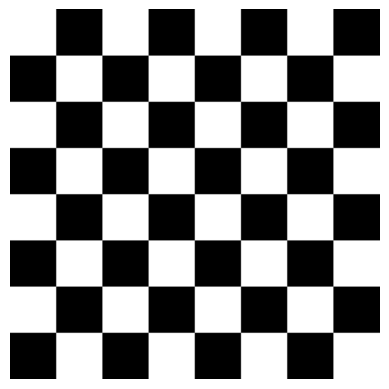

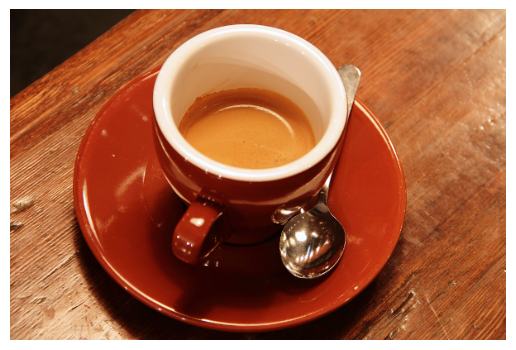

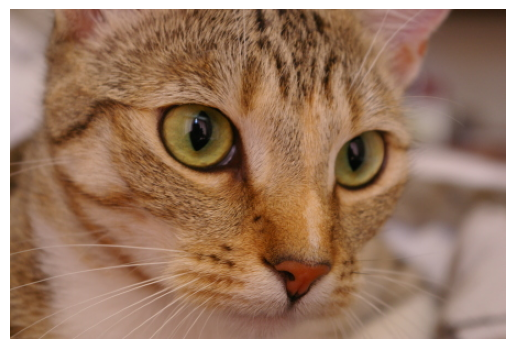

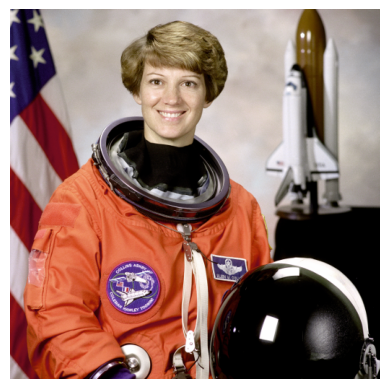

In [23]:
import matplotlib.pyplot as plt
import numpy as np
from skimage import data

checkerboard = (data.checkerboard() > 127).astype(np.uint8) * 255
checkerboard = np.repeat(checkerboard[..., np.newaxis], 3, axis=-1)

imgs_color = [checkerboard, data.coffee(), data.cat(), data.astronaut()]
image_names = ["checkerboard", "coffee", "cat", "astronaut"]

for img in imgs_color:
    plt.imshow(img)
    plt.axis('off')
    plt.show()

## Implementation

### Pairs, differences and range

1. Split the channel (flattened in raster order) into non-overlapping blocks of two consecutive pixels `(p_i, p_i+1)`; if the pixel count is odd, the last pixel is left untouched
2. Calculate the difference of a block: `d = |p_i - p_i+1|`; small `d` means smooth area, large `d` means edge
3. Find the range `[l, u]` that contains `d`. The range table is fixed: `[0, 7]`, `[8, 15]`, `[16, 31]`, `[32, 63]`, `[64, 127]`, `[128, 255]`; width is `w = u - l + 1`
4. The threshold `div = 15` splits blocks into two kinds, and each kind hides a different number of bits:
    - smooth block (`d <= div`, the first two ranges): the 3 least significant bits of each pixel are replaced by secret bits (6 bits per block)
    - edge block (`d > div`): `d` is moved inside its range (PVD); the wider the range, the more bits fit: `floor(log2(w))` (4, 5, 6 or 7 bits)

In [24]:
channel_names = ["R", "G", "B"]
division = 15

# split channel into pairs of pixels
def split_into_pairs(channel):
    flat = channel.ravel().astype(np.int16)
    return flat[:len(flat) // 2 * 2].reshape(-1, 2)

# get the range for a given difference
def find_range(difference):
    range_table = [(0, 7), (8, 15), (16, 31), (32, 63), (64, 127), (128, 255)]
    for lower_bound, upper_bound in range_table:
        if lower_bound <= difference <= upper_bound:
            return lower_bound, upper_bound

In [25]:
for pixel_pair in [(100, 162), (30, 15)]:
    difference = abs(pixel_pair[0] - pixel_pair[1])
    lower_bound, upper_bound = find_range(difference)
    if difference <= division:
        hidden_bits = 6
    else:
        hidden_bits = int(np.log2(upper_bound - lower_bound + 1))

    print(f"pair={pixel_pair}, d={difference}, range=[{lower_bound}, {upper_bound}], hidden bits={hidden_bits}")

pair=(100, 162), d=62, range=[32, 63], hidden bits=5
pair=(30, 15), d=15, range=[8, 15], hidden bits=6


### Embedding and extraction for one pair

Embedding (`bits` has as many elements as the block hides):
- smooth block: replace the 3 LSBs of the first pixel with `bits[:3]` and of the second pixel with `bits[3:]`; if the new difference `d'` exceeds `div`, move the pixels 8 levels towards each other (`+/-8` keeps the 3 LSBs, so the hidden bits survive)
- edge block: read the bits as a number `b`, set the new difference `d' = l + b` (inside the same range `[l, u]`), and spread the change `m = |d' - d|` over both pixels: one gets `ceil(m / 2)`, the other `floor(m / 2)`; the direction depends on which pixel is larger and on whether `d'` grows or shrinks

Extraction needs only the modified pair: a pair with `d' <= div` hides the 3 + 3 LSBs of its pixels, any other pair hides `d' - l` written on `floor(log2(w))` bits

In [26]:
# number of secret bits hidden in a block with a given difference
def count_hidden_bits(difference):
    if difference <= division:
        return 6
    lower_bound, upper_bound = find_range(difference)
    return int(np.log2(upper_bound - lower_bound + 1))

In [27]:
def bits_to_integer(bits):
    return int("".join(map(str, bits)), 2)

def integer_to_bits(value, bit_count):
    return [int(bit) for bit in format(value, f"0{bit_count}b")]

In [28]:
def embed_pair(first_pixel, second_pixel, bits):
    difference = abs(first_pixel - second_pixel)

    if difference <= division:
        # smooth block
        # replace 3 LSBs of each pixel
        new_first = (first_pixel & ~7) | bits_to_integer(bits[:3])
        new_second = (second_pixel & ~7) | bits_to_integer(bits[3:])

        # if the difference grew into the edge level, bring pixels back together
        if abs(new_first - new_second) > division:
            shift = 8 if new_first < new_second else -8
            new_first += shift
            new_second -= shift

    else:
        # edge block
        # move difference to l + b inside the same range
        lower_bound, _ = find_range(difference)
        new_difference = lower_bound + bits_to_integer(bits)
        change = abs(new_difference - difference)
        change_rounded_up, change_rounded_down = (change + 1) // 2, change // 2

        is_first_larger = first_pixel >= second_pixel
        difference_grows = new_difference > difference

        if is_first_larger and difference_grows:
            new_first, new_second = first_pixel + change_rounded_up, second_pixel - change_rounded_down
        elif not is_first_larger and difference_grows:
            new_first, new_second = first_pixel - change_rounded_down, second_pixel + change_rounded_up
        elif is_first_larger:
            new_first, new_second = first_pixel - change_rounded_up, second_pixel + change_rounded_down
        else:
            new_first, new_second = first_pixel + change_rounded_up, second_pixel - change_rounded_down

    return new_first, new_second

In [29]:
def extract_pair(first_pixel, second_pixel):
    difference = abs(first_pixel - second_pixel)

    if difference <= division:
        return integer_to_bits(first_pixel & 7, 3) + integer_to_bits(second_pixel & 7, 3)

    lower_bound, _ = find_range(difference)
    return integer_to_bits(difference - lower_bound, count_hidden_bits(difference))

### Embedding and extraction for a channel

Blocks are processed in raster order; each one takes as many bits from the payload as it can hide (`count_hidden_bits`). The last block is padded with zeros when the payload ends in the middle of it.

In [30]:
def embed_channel(channel, bits):

    # split image into pairs
    pairs = split_into_pairs(channel)

    marked_pairs = pairs.copy()
    skipped_pairs = []
    embedded_bit_count = 0

    for pair_index, (first_pixel, second_pixel) in enumerate(pairs):
        if embedded_bit_count >= len(bits):
            break

        # take bits for current block, pad the last block with zeros
        bit_count = count_hidden_bits(abs(first_pixel - second_pixel))
        block_bits = list(bits[embedded_bit_count:embedded_bit_count + bit_count])
        block_bits += [0] * (bit_count - len(block_bits))

        new_first, new_second = embed_pair(int(first_pixel), int(second_pixel), block_bits)

        if 0 <= new_first <= 255 and 0 <= new_second <= 255:
            marked_pairs[pair_index] = (new_first, new_second)
            embedded_bit_count += bit_count
        else:
            skipped_pairs.append(pair_index)

    marked = channel.ravel().copy()
    marked[:marked_pairs.size] = marked_pairs.ravel()
    return marked.reshape(channel.shape), skipped_pairs, min(embedded_bit_count, len(bits))

In [31]:
def extract_channel(marked_channel, skipped_pairs, bit_count):
    extracted_bits = []

    for pair_index, (first_pixel, second_pixel) in enumerate(split_into_pairs(marked_channel)):
        if len(extracted_bits) >= bit_count:
            break
        if pair_index not in skipped_pairs:
            extracted_bits += extract_pair(int(first_pixel), int(second_pixel))

    return extracted_bits[:bit_count]

### Usage

Random payload is embedded and extracted for value comparison. Distortion is measured in Peak Signal-to-Noise Ratio (PSNR). The method is not reversible, so the figure compares the raw image (first column) with the marked one (second column).

checkerboard  R: capacity= 120800, embedded= 120800, skipped=   0, PSNR=29.74 dB, recovered=True
checkerboard  G: capacity= 120800, embedded= 120800, skipped=   0, PSNR=29.51 dB, recovered=True
checkerboard  B: capacity= 120800, embedded= 120800, skipped=   0, PSNR=29.76 dB, recovered=True
coffee        R: capacity= 694155, embedded= 693311, skipped= 158, PSNR=36.90 dB, recovered=True
coffee        G: capacity= 695480, embedded= 694383, skipped= 193, PSNR=36.58 dB, recovered=True
coffee        B: capacity= 697631, embedded= 695276, skipped= 444, PSNR=36.67 dB, recovered=True
cat           R: capacity= 395142, embedded= 395142, skipped=   0, PSNR=37.36 dB, recovered=True
cat           G: capacity= 395759, embedded= 395759, skipped=   0, PSNR=37.39 dB, recovered=True
cat           B: capacity= 396213, embedded= 396106, skipped=  20, PSNR=37.44 dB, recovered=True
astronaut     R: capacity= 764840, embedded= 763155, skipped= 317, PSNR=36.54 dB, recovered=True
astronaut     G: capacity= 763

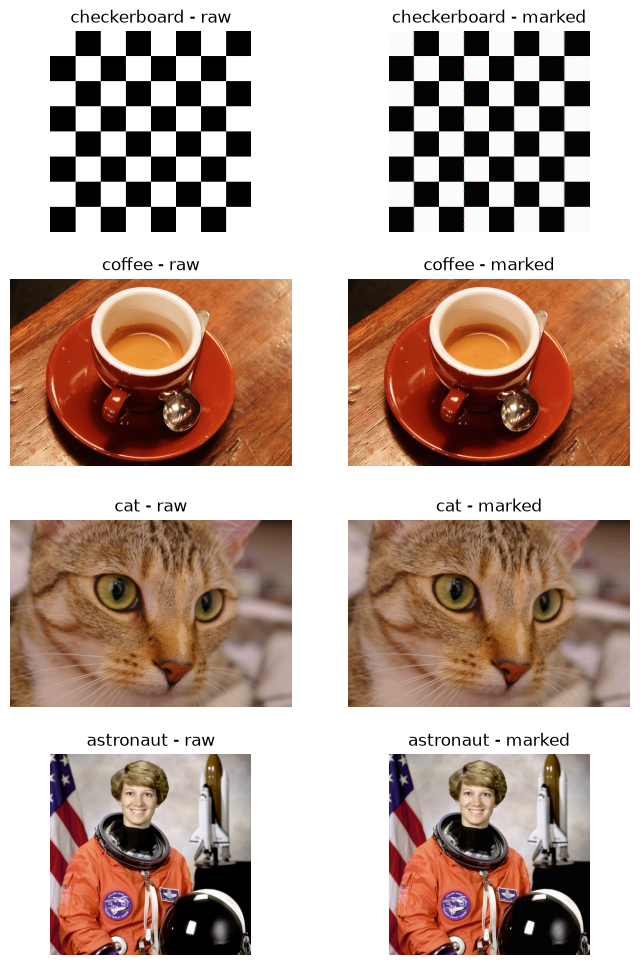

In [32]:
from skimage.metrics import peak_signal_noise_ratio

rng = np.random.default_rng()
figure, axes = plt.subplots(len(imgs_color), 2, figsize=(8, 12))

for row, (image_name, image) in enumerate(zip(image_names, imgs_color)):

    marked_channels = []

    for channel_index, channel_name in enumerate(channel_names):
        channel = image[:, :, channel_index]

        # capacity of the whole channel, may be reduced by blocks that cannot be used
        pairs = split_into_pairs(channel)
        capacity = sum(count_hidden_bits(abs(first_pixel - second_pixel)) for first_pixel, second_pixel in pairs)

        # generate random binary payload
        bits = rng.integers(0, 2, size=capacity).tolist()

        marked, skipped_pairs, embedded_bit_count = embed_channel(channel, bits)
        extracted_bits = extract_channel(marked, skipped_pairs, embedded_bit_count)

        marked_channels.append(marked)

        # check if extracted information is the same
        recovered = extracted_bits == bits[:embedded_bit_count]

        psnr = peak_signal_noise_ratio(channel, marked)
        
        print(f"{image_name:13s} {channel_name}: capacity={capacity:7d}, embedded={embedded_bit_count:7d}, skipped={len(skipped_pairs):4d}, PSNR={psnr:.2f} dB, recovered={recovered}")

    axes[row, 0].imshow(image)
    axes[row, 0].set_title(f"{image_name} - raw")
    axes[row, 1].imshow(np.stack(marked_channels, axis=-1))
    axes[row, 1].set_title(f"{image_name} - marked")

for axis in axes.ravel():
    axis.axis("off")

plt.show()